<a href="https://colab.research.google.com/github/famub/2026-GP1-02/blob/main/models/Xception_5class_Std_Seeds.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MUFSAL - Xception (5 classes) + Joint-Aware Crop + Multiple Seeds



## 1)

In [ ]:
!pip install -q timm kagglehub

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ---------- Settings ----------
from pathlib import Path

SEEDS = [42, 41, 7]
OUT_DIR = Path('/content/drive/MyDrive/MUFSAL/Xception_5class_SmartCrop')
REQUIRE_GPU = True
EXPECTED_SIZES = {'train': 5778, 'val': 826, 'test': 1656}
PRETRAINED = True
NUM_WORKERS = 2

# Stage 1 = same settings as Exp1
STAGE1 = dict(epochs=20, batch_size=32, lr=1e-4)
# Stage 2 = same settings as Exp7
STAGE2 = dict(epochs=20, patience=5, batch_size=16, lr=5e-6, weight_decay=1e-3, label_smoothing=0.05)

SPLIT_NOTE = 'Default Kaggle train/val/test folders. auto_test is not used.'
OUT_DIR.mkdir(parents=True, exist_ok=True)
print('Results folder:', OUT_DIR)

Results folder: /content/drive/MyDrive/MUFSAL/Xception_5class_SmartCrop


In [ ]:
import copy, json, os, random, time
import numpy as np
import pandas as pd
import cv2
import torch, torch.nn as nn, torch.nn.functional as F
import timm
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks
from sklearn.metrics import (accuracy_score, f1_score, cohen_kappa_score,
                             classification_report, confusion_matrix, recall_score)
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if REQUIRE_GPU and device.type != 'cuda':
    raise RuntimeError('No GPU found. Runtime > Change runtime type > T4 GPU, then Run all.')
print('Device:', device, '| GPU:', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'none')

Device: cuda | GPU: Tesla T4


## 2)   (Seeds)


In [ ]:
def set_seed(seed):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

## 3)   (SmartCrop)


In [ ]:
import kagglehub
DATA_DIR = kagglehub.dataset_download('shashwatwork/knee-osteoarthritis-dataset-with-severity')
print('Dataset:', DATA_DIR, '|', sorted(os.listdir(DATA_DIR)))

Using Colab cache for faster access to the 'knee-osteoarthritis-dataset-with-severity' dataset.
Dataset: /kaggle/input/knee-osteoarthritis-dataset-with-severity | ['auto_test', 'test', 'train', 'val']


In [ ]:
SIZE = 224
WINDOW_H = 104      # final image is 224 x 104
PRIOR_ROW = 124     # median joint row
MAX_SHIFT = 16      # max shift from PRIOR_ROW
FALLBACK_ROW = 124  # used when no joint is found

class Denoise:
    def __call__(self, img):
        g = np.array(img.convert('L'))
        g = cv2.GaussianBlur(g, (3, 3), 0)
        g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)
        return Image.fromarray(g)

def find_joint_row(gray, lo=0.40, hi=0.70, min_prom=4):
    H, W = gray.shape
    cols = gray[:, int(W * 0.25):int(W * 0.75)].astype(np.float32)
    prof = gaussian_filter1d(cols.mean(axis=1), sigma=H * 0.02)
    a, b = int(H * lo), int(H * hi)
    peaks, props = find_peaks(-prof[a:b], prominence=min_prom)
    if len(peaks) == 0:
        return None
    return a + int(peaks[np.argmax(props['prominences'])])

class SmartCrop:
    def __init__(self):
        self.denoise = Denoise()
    def __call__(self, img):
        img = img.convert('L').resize((SIZE, SIZE))
        row = find_joint_row(np.array(img))     # detect on the raw image
        self.last_found = row is not None
        center = FALLBACK_ROW if row is None else int(np.clip(row, PRIOR_ROW - MAX_SHIFT, PRIOR_ROW + MAX_SHIFT))
        top = center - WINDOW_H // 2
        return self.denoise(img).crop((0, top, SIZE, top + WINDOW_H))

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
norm = [transforms.ToTensor(), transforms.Normalize(MEAN, STD)]

eval_tf = transforms.Compose([transforms.Grayscale(3)] + norm)
stage1_train_tf = transforms.Compose([      # Exp1 augmentation
    transforms.Grayscale(3),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
] + norm)
stage2_train_tf = transforms.Compose([      # Exp7 augmentation
    transforms.Grayscale(3),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=5),
] + norm)

class CachedKnee(Dataset):
    def __init__(self, split):
        base = datasets.ImageFolder(f'{DATA_DIR}/{split}')
        self.samples, self.targets, self.classes = base.samples, base.targets, base.classes
        crop = SmartCrop()
        self.items, found = [], 0
        for path, _ in base.samples:
            with Image.open(path) as im:
                self.items.append(crop(im))
            found += crop.last_found
        self.found = found
        self.transform = None
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        return self.transform(self.items[i]), self.targets[i]
    def with_transform(self, tf):
        other = copy.copy(self)
        other.transform = tf
        return other

t0 = time.time()
data = {s: CachedKnee(s) for s in ['train', 'val', 'test']}
print(f'Preprocessing took {(time.time()-t0)/60:.1f} min')
for s, d in data.items():
    assert len(d) == EXPECTED_SIZES[s], f'{s}: expected {EXPECTED_SIZES[s]}, got {len(d)}'
    print(f'{s:5s} images: {len(d)} | joint found: {d.found} ({100*d.found/len(d):.1f}%) | classes: {d.classes}')
assert data['train'].items[0].size == (224, 104), data['train'].items[0].size

counts = np.bincount(data['train'].targets, minlength=5)
class_weights = torch.tensor(counts.sum() / (5 * counts), dtype=torch.float)
print('Class weights:', [round(float(w), 2) for w in class_weights])

Preprocessing took 1.7 min
train images: 5778 | joint found: 5557 (96.2%) | classes: ['0', '1', '2', '3', '4']
val   images: 826 | joint found: 784 (94.9%) | classes: ['0', '1', '2', '3', '4']
test  images: 1656 | joint found: 1598 (96.5%) | classes: ['0', '1', '2', '3', '4']
Class weights: [0.51, 1.1, 0.76, 1.53, 6.68]


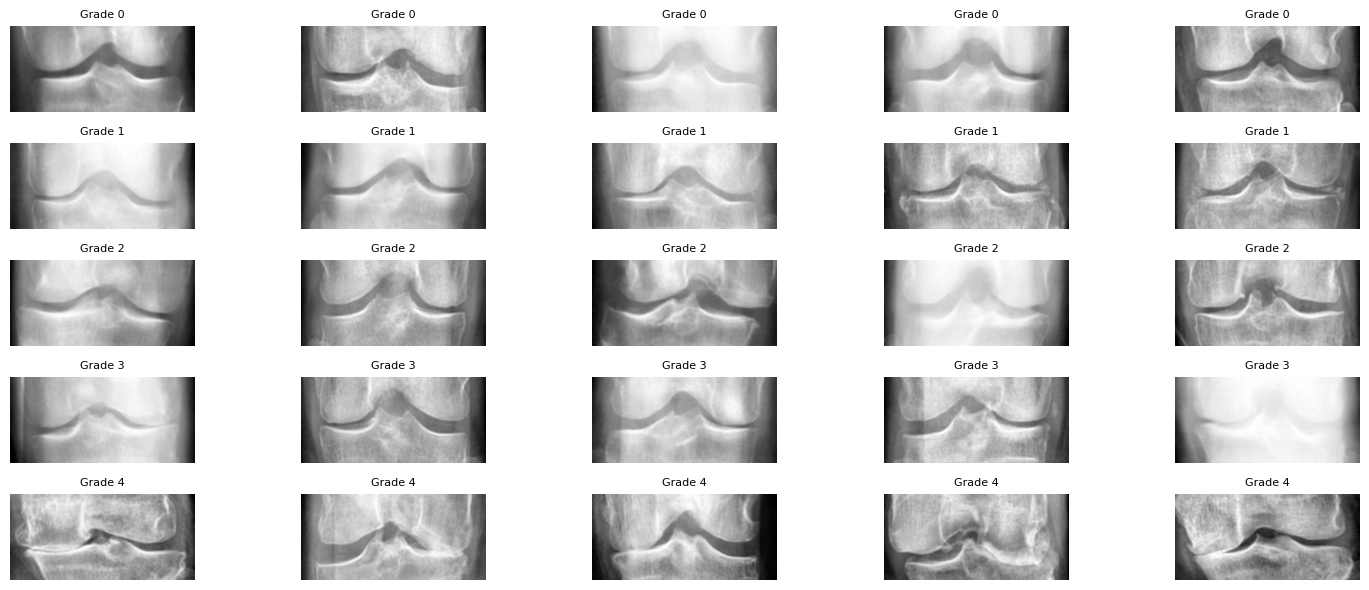

In [ ]:
# Visual check: 5 cropped images per grade
fig, axes = plt.subplots(5, 5, figsize=(15, 6))
for grade in range(5):
    idx = [i for i, y in enumerate(data['train'].targets) if y == grade][:5]
    for ax, i in zip(axes[grade], idx):
        ax.imshow(data['train'].items[i], cmap='gray')
        ax.set_title(f'Grade {grade}', fontsize=8)
        ax.axis('off')
plt.tight_layout(); plt.show()

## 4) Training

Stage 1 (Exp1): Adam with lr 0.0001, Weighted CE, 20 epochs, and best Val Accuracy.

Stage 2 (Exp7): Starts from Stage 1 weights using AdamW with lr 0.000005, label smoothing of 0.05, best Val Macro-F1, and patience 5.

In [ ]:
def make_loader(split, tf, batch_size, shuffle=False, seed=0):
    return DataLoader(data[split].with_transform(tf), batch_size=batch_size, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=device.type == 'cuda',
                      worker_init_fn=seed_worker, generator=torch.Generator().manual_seed(seed))

def build_model(pretrained):
    return timm.create_model('legacy_xception.tf_in1k', pretrained=pretrained, num_classes=5).to(device)

@torch.no_grad()
def predict(model, loader):
    model.eval()
    y_true, y_pred = [], []
    for x, y in loader:
        y_pred.extend(model(x.to(device)).argmax(1).cpu().numpy().tolist())
        y_true.extend(y.numpy().tolist())
    return np.array(y_true), np.array(y_pred)

def compute_metrics(y, p):
    return {
        'accuracy': 100 * accuracy_score(y, p),
        'macro_f1': f1_score(y, p, average='macro', zero_division=0),
        'qwk': cohen_kappa_score(y, p, labels=list(range(5)), weights='quadratic'),
        'recall_per_grade': [round(float(r), 4) for r in recall_score(y, p, labels=list(range(5)), average=None, zero_division=0)],
    }

def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    correct, total, running = 0, 0, 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        running += loss.item() * y.size(0)
        correct += (out.argmax(1) == y).sum().item()
        total += y.size(0)
    return running / total, 100 * correct / total

def run_stage1(seed, folder):
    path, done = folder / 'stage1_best.pth', folder / 'stage1_done.json'
    if path.exists() and done.exists():
        print(f'[seed {seed}] Stage 1 already finished, skipping.')
        return path
    set_seed(seed)
    model = build_model(PRETRAINED)
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
    optimizer = torch.optim.Adam(model.parameters(), lr=STAGE1['lr'])
    train_loader = make_loader('train', stage1_train_tf, STAGE1['batch_size'], True, seed)
    val_loader = make_loader('val', eval_tf, 32)
    best, best_epoch = -1.0, 0
    for epoch in range(1, STAGE1['epochs'] + 1):
        t0 = time.time()
        loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        m = compute_metrics(*predict(model, val_loader))
        print(f"[seed {seed} S1] {epoch:02d}/{STAGE1['epochs']} | loss {loss:.4f} | train {tr_acc:.2f}% | "
              f"val {m['accuracy']:.2f}% | F1 {m['macro_f1']:.3f} | QWK {m['qwk']:.4f} | {time.time()-t0:.0f}s", flush=True)
        if m['accuracy'] > best:
            best, best_epoch = m['accuracy'], epoch
            torch.save(model.state_dict(), path)
    done.write_text(json.dumps({'best_val_acc': best, 'best_epoch': best_epoch}))
    return path

def run_stage2(seed, folder, stage1_path):
    path, done = folder / 'stage2_best.pth', folder / 'stage2_done.json'
    if path.exists() and done.exists():
        print(f'[seed {seed}] Stage 2 already finished, skipping.')
        return path
    set_seed(seed)
    model = build_model(False)
    model.load_state_dict(torch.load(stage1_path, map_location=device, weights_only=True))
    criterion = nn.CrossEntropyLoss(label_smoothing=STAGE2['label_smoothing'])
    optimizer = torch.optim.AdamW(model.parameters(), lr=STAGE2['lr'], weight_decay=STAGE2['weight_decay'])
    train_loader = make_loader('train', stage2_train_tf, STAGE2['batch_size'], True, seed + 1000)
    val_loader = make_loader('val', eval_tf, 32)
    best, best_epoch, wait = -1.0, 0, 0
    for epoch in range(1, STAGE2['epochs'] + 1):
        t0 = time.time()
        loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        m = compute_metrics(*predict(model, val_loader))
        print(f"[seed {seed} S2] {epoch:02d}/{STAGE2['epochs']} | loss {loss:.4f} | train {tr_acc:.2f}% | "
              f"val {m['accuracy']:.2f}% | F1 {m['macro_f1']:.3f} | QWK {m['qwk']:.4f} | {time.time()-t0:.0f}s", flush=True)
        if m['macro_f1'] > best:
            best, best_epoch, wait = m['macro_f1'], epoch, 0
            torch.save(model.state_dict(), path)
        else:
            wait += 1
            if wait >= STAGE2['patience']:
                print('Early stopping.')
                break
    done.write_text(json.dumps({'best_val_f1': best, 'best_epoch': best_epoch}))
    return path

def evaluate_seed(seed, folder, weights):
    model = build_model(False)
    model.load_state_dict(torch.load(weights, map_location=device, weights_only=True))
    val = compute_metrics(*predict(model, make_loader('val', eval_tf, 32)))
    y, p = predict(model, make_loader('test', eval_tf, 32))
    test = compute_metrics(y, p)
    result = {'seed': seed, 'val': val, 'test': test,
              'confusion_matrix': confusion_matrix(y, p, labels=list(range(5))).tolist(),
              'stage1': json.loads((folder / 'stage1_done.json').read_text()),
              'stage2': json.loads((folder / 'stage2_done.json').read_text())}
    pd.DataFrame({'path': [s[0] for s in data['test'].samples], 'true': y, 'pred': p}).to_csv(folder / 'test_predictions.csv', index=False)
    (folder / 'classification_report.txt').write_text(
        classification_report(y, p, labels=list(range(5)), target_names=data['test'].classes, zero_division=0))
    (folder / 'result.json').write_text(json.dumps(result, indent=2))
    return result

In [ ]:
for seed in SEEDS:
    folder = OUT_DIR / f'seed_{seed}'
    folder.mkdir(parents=True, exist_ok=True)
    if (folder / 'result.json').exists():
        print(f'[seed {seed}] Already finished, skipping.')
        continue
    start = time.time()
    s1 = run_stage1(seed, folder)
    s2 = run_stage2(seed, folder, s1)
    r = evaluate_seed(seed, folder, s2)
    print(f"[seed {seed}] DONE in {(time.time()-start)/60:.1f} min | TEST acc {r['test']['accuracy']:.2f}% | "
          f"F1 {r['test']['macro_f1']:.3f} | QWK {r['test']['qwk']:.4f}", flush=True)

Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth
[seed 42 S1] 01/20 | loss 1.2885 | train 41.92% | val 49.64% | F1 0.513 | QWK 0.6517 | 45s
[seed 42 S1] 02/20 | loss 0.9390 | train 54.71% | val 54.48% | F1 0.554 | QWK 0.7310 | 47s
[seed 42 S1] 03/20 | loss 0.8079 | train 59.48% | val 54.84% | F1 0.591 | QWK 0.6972 | 52s
[seed 42 S1] 04/20 | loss 0.7440 | train 63.12% | val 56.05% | F1 0.579 | QWK 0.6854 | 50s
[seed 42 S1] 05/20 | loss 0.6683 | train 65.33% | val 61.02% | F1 0.630 | QWK 0.7426 | 51s
[seed 42 S1] 06/20 | loss 0.6106 | train 68.29% | val 55.69% | F1 0.615 | QWK 0.7259 | 51s
[seed 42 S1] 07/20 | loss 0.5563 | train 71.69% | val 59.81% | F1 0.633 | QWK 0.7361 | 50s
[seed 42 S1] 08/20 | loss 0.5033 | train 75.34% | val 60.65% | F1 0.640 | QWK 0.7579 | 50s
[seed 42 S1] 09/20 | loss 0.4372 | train 78.73% | val 56.90% | F1 0.588 | QWK 0.7166 | 50s
[s

## 5) Results


,Seed 42,Seed 41,Seed 7,Mean,SD
Validation QWK,0.7350,0.7260,0.7580,0.7397,0.0165
Test Accuracy (%),63.5266,60.6884,60.5072,61.5741,1.6933
Test Macro-F1,0.6285,0.6348,0.6210,0.6281,0.0069
Test QWK,0.7544,0.7868,0.7415,0.7609,0.0233


,Seed 42,Seed 41,Seed 7,Mean
KL0 recall,0.909,0.710,0.751,0.790
KL1 recall,0.145,0.290,0.240,0.225
KL2 recall,0.514,0.550,0.575,0.547
KL3 recall,0.695,0.789,0.677,0.720
KL4 recall,0.843,0.843,0.843,0.843


Reference, old Exp7 without crop and without a fixed seed: Test Acc 61.84% | Macro-F1 0.631 | QWK 0.7817


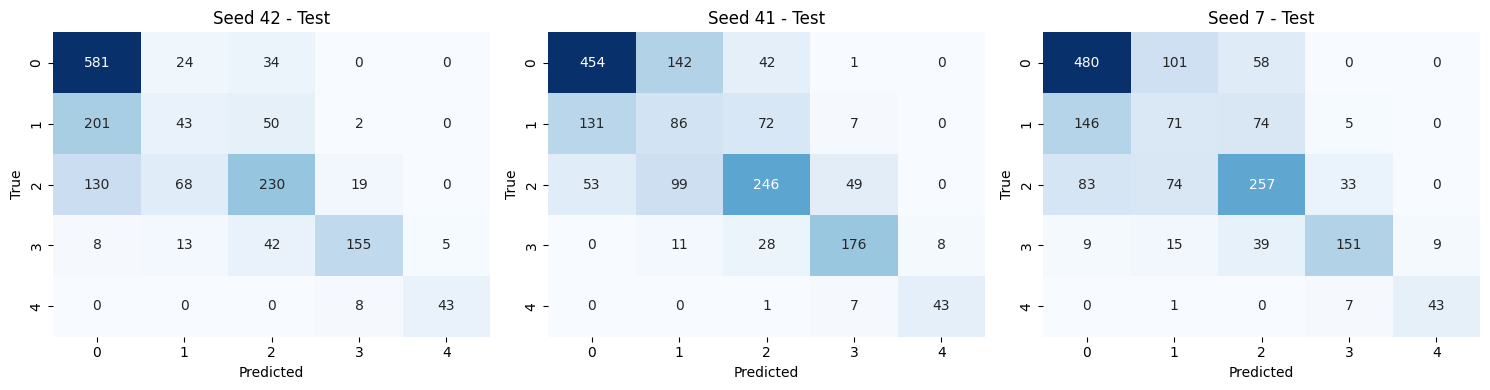

In [ ]:
results = [json.loads((OUT_DIR / f'seed_{s}' / 'result.json').read_text()) for s in SEEDS
           if (OUT_DIR / f'seed_{s}' / 'result.json').exists()]
assert len(results) == len(SEEDS), 'Some seeds have not finished. Run all again.'

rows = [('Validation QWK', 'val', 'qwk'), ('Test Accuracy (%)', 'test', 'accuracy'),
        ('Test Macro-F1', 'test', 'macro_f1'), ('Test QWK', 'test', 'qwk')]
table = {f"Seed {r['seed']}": [r[a][b] for _, a, b in rows] for r in results}
df = pd.DataFrame(table, index=[n for n, _, _ in rows])
df['Mean'] = df.mean(axis=1)
df['SD'] = df[[c for c in df.columns if c.startswith('Seed')]].std(axis=1, ddof=1)
df.to_csv(OUT_DIR / 'summary.csv')
display(df.round(4))

recall = pd.DataFrame({f"Seed {r['seed']}": r['test']['recall_per_grade'] for r in results},
                      index=[f'KL{g} recall' for g in range(5)])
recall['Mean'] = recall.mean(axis=1)
display(recall.round(3))

print('Reference, old Exp7 without crop and without a fixed seed: '
      'Test Acc 61.84% | Macro-F1 0.631 | QWK 0.7817')

fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 4), squeeze=False)
for ax, r in zip(axes[0], results):
    sns.heatmap(np.array(r['confusion_matrix']), annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(f"Seed {r['seed']} - Test"); ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.tight_layout(); plt.savefig(OUT_DIR / 'confusion_matrices.png', dpi=200); plt.show()

## 6) Grad-CAM


Seed shown (highest Validation QWK): 7


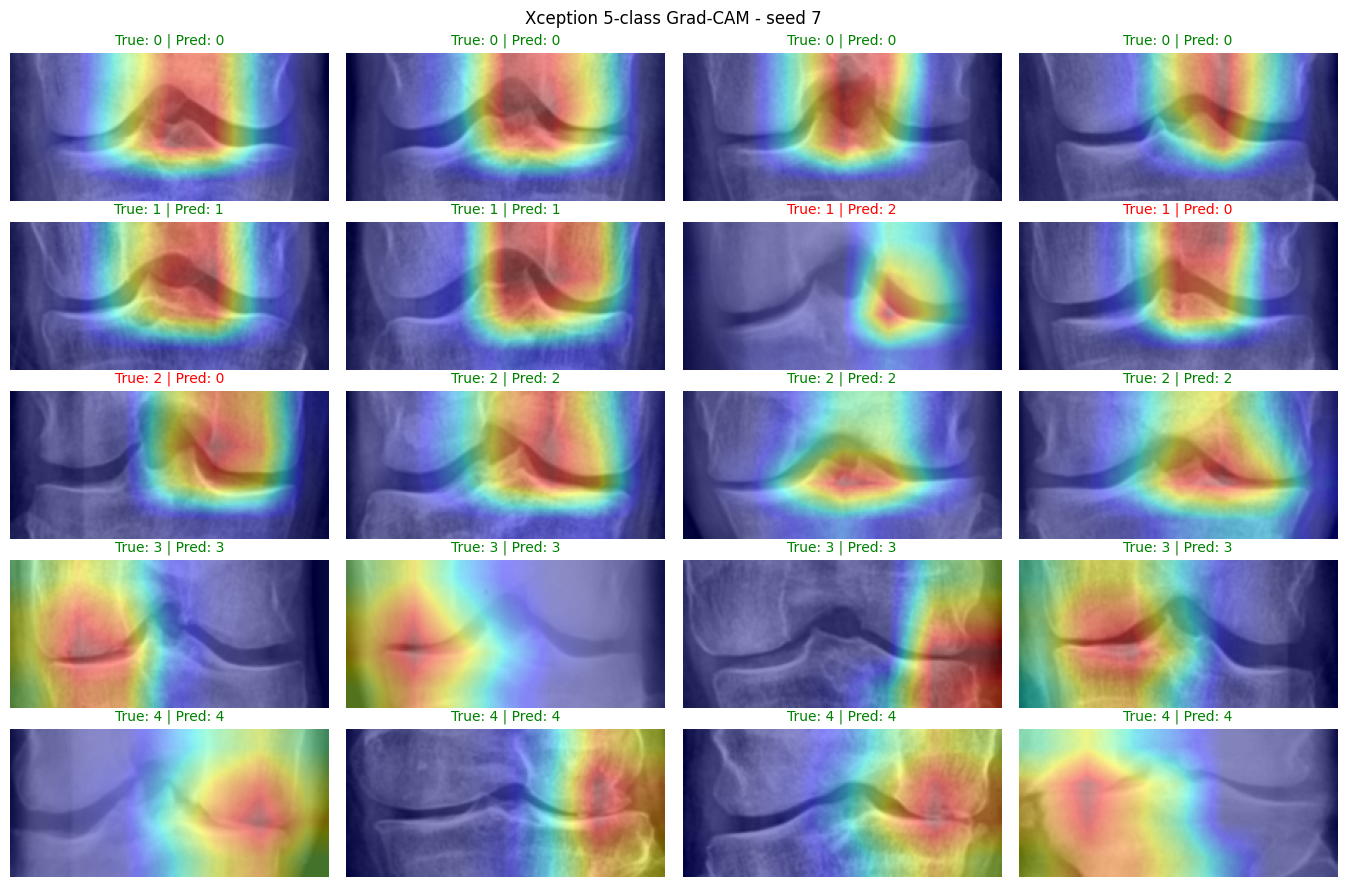

Grad-CAM figures saved for all seeds in /content/drive/MyDrive/MUFSAL/Xception_5class_SmartCrop


In [ ]:
class GradCAM:
    def __init__(self, model, layer):
        self.model = model
        self.handle = layer.register_forward_hook(self._hook)
    def _hook(self, module, inputs, output):
        self.activations = output
        output.register_hook(lambda g: setattr(self, 'gradients', g))
    def __call__(self, x):
        self.model.zero_grad(set_to_none=True)
        out = self.model(x)
        pred = int(out.argmax(1))
        out[0, pred].backward()
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * self.activations).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[2:], mode='bilinear', align_corners=False)[0, 0]
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        return cam.detach().cpu().numpy(), pred
    def close(self):
        self.handle.remove()

def gradcam_figure(seed, n=4):
    model = build_model(False)
    model.load_state_dict(torch.load(OUT_DIR / f'seed_{seed}' / 'stage2_best.pth', map_location=device, weights_only=True))
    model.eval()
    cam = GradCAM(model, model.act4)
    ds = data['test'].with_transform(eval_tf)
    fig, axes = plt.subplots(5, n, figsize=(3.4 * n, 9), squeeze=False)
    for grade in range(5):
        idx = [i for i, y in enumerate(ds.targets) if y == grade][:n]
        for ax, i in zip(axes[grade], idx):
            x, y = ds[i]
            heat, pred = cam(x.unsqueeze(0).to(device))
            ax.imshow(ds.items[i], cmap='gray')
            ax.imshow(heat, cmap='jet', alpha=0.45, vmin=0, vmax=1)
            ax.set_title(f'True: {y} | Pred: {pred}', fontsize=10, color='green' if y == pred else 'red')
            ax.axis('off')
    cam.close()
    fig.suptitle(f'Xception 5-class Grad-CAM - seed {seed}')
    plt.tight_layout()
    fig.savefig(OUT_DIR / f'seed_{seed}' / 'gradcam_5class.png', dpi=200)
    return fig

chosen = max(results, key=lambda r: r['val']['qwk'])['seed']
print('Seed shown (highest Validation QWK):', chosen)
for s in SEEDS:
    fig = gradcam_figure(s)
    if s == chosen:
        plt.show()
    else:
        plt.close(fig)
print('Grad-CAM figures saved for all seeds in', OUT_DIR)